# KuaiRand data exploration

## Loading data

In [1]:
from pathlib import Path

if not Path("KuaiRand-1K").exists():
    !tar -xzvf KuaiRand-1K.tar.gz
else:
    print("KuaiRand-1K già estratta, salto l'estrazione.")

KuaiRand-1K già estratta, salto l'estrazione.


In [2]:
from pathlib import Path
import tarfile
import urllib.request
import sys

# Unica variabile da cambiare. Colab: "."  |  In locale: una cartella fuori da OneDrive, es. Path(r"C:\dati")
ROOT = Path(".")
DATA_DIR = Path.joinpath(ROOT,"KuaiRand-1K","data") 
URL = "https://zenodo.org/records/10439422/files/KuaiRand-1K.tar.gz"

if not DATA_DIR.exists():
    archive = ROOT / "KuaiRand-1K.tar.gz"
    if not archive.exists():
        print("Scarico l'archivio (~1,1 GB)...")
        urllib.request.urlretrieve(URL, archive)
    print("Estraggo...")
    with tarfile.open(archive, "r:gz") as tf:
        tf.extractall(ROOT, filter="data")

for f in sorted(DATA_DIR.iterdir()):
    print(f"{f.name:40s} {f.stat().st_size / 1e6:8.0f} MB")

log_random_4_22_to_5_08_1k.csv                  3 MB
log_standard_4_08_to_4_21_1k.csv              374 MB
log_standard_4_22_to_5_08_1k.csv              492 MB
user_features_1k.csv                            0 MB
video_features_basic_1k.csv                   377 MB
video_features_statistic_1k.csv              3371 MB


In [3]:
import pandas as pd
from matplotlib import pyplot as plt

# 3.1 User_features_1K exploration

The interaction logs record what happens when a user is shown a video.
The user profile table describes the people behind those interactions.
Throughout this notebook, each user receives the same weight, regardless
of how many videos they watched.

Our first question is whether `user_id` identifies exactly one profile.
This matters when we later join profiles to impressions. A repeated profile
could cause the same impression to appear several times after the join.

In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Run from Project_AI_industry. If the CSV is next to the notebook,
# use Path("user_features_1k.csv") instead.
path = Path("KuaiRand-1K") / "data" / "user_features_1k.csv"
users = pd.read_csv(path)

print("Rows and columns:", users.shape)
print("Distinct user IDs:", users["user_id"].nunique())
print("Missing user IDs:", users["user_id"].isna().sum())
print("Repeated user IDs:", users["user_id"].duplicated().sum())

with pd.option_context("display.max_columns", None):
    display(users.head(3))

Rows and columns: (1000, 31)
Distinct user IDs: 1000
Missing user IDs: 0
Repeated user IDs: 0


,user_id,user_active_degree,is_lowactive_period,is_live_streamer,is_video_author,follow_user_num,follow_user_num_range,fans_user_num,fans_user_num_range,friend_user_num,friend_user_num_range,register_days,register_days_range,onehot_feat0,onehot_feat1,onehot_feat2,onehot_feat3,onehot_feat4,onehot_feat5,onehot_feat6,onehot_feat7,onehot_feat8,onehot_feat9,onehot_feat10,onehot_feat11,onehot_feat12,onehot_feat13,onehot_feat14,onehot_feat15,onehot_feat16,onehot_feat17
0,0,full_active,0,1,1,514,500+,150,"[100,1k)",34,"[30,60)",799,730+,1,1,29,949,1.0,0,0,14,135,6,3,0,0.0,1.0,0.0,0.0,0.0,0.0
1,1,full_active,0,-124,1,457,"(250,500]",20,"[10,100)",3,"[1,5)",1474,730+,1,3,2,1160,4.0,0,0,31,283,6,2,2,1.0,0.0,1.0,0.0,0.0,0.0
2,2,full_active,0,-124,1,8,"(0,10]",26,"[10,100)",3,"[1,5)",231,181-365,1,0,2,1176,2.0,0,0,31,275,5,2,2,0.0,0.0,0.0,1.0,0.0,0.0


## 3.2 Activity labels and account indicators

How much of the sample belongs to each activity group? We count users in
each category and show the counts alongside percentages. A group of two
users and a group of 640 users provide very different amounts of evidence.

We also inspect the recorded values of three account indicators. This lets
us check whether the values can be interpreted as ordinary yes/no answers.

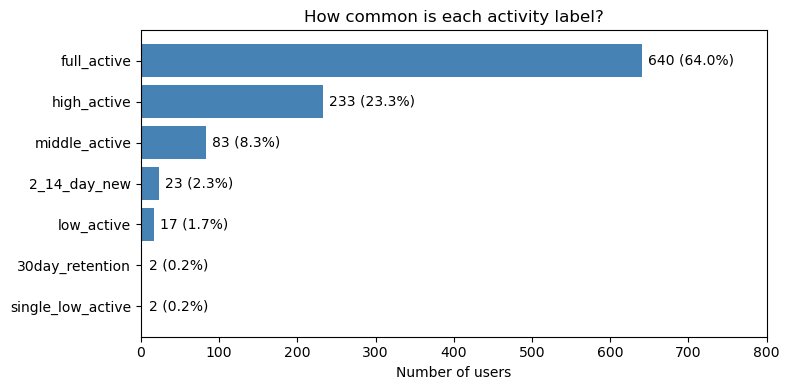


is_video_author
is_video_author
0    192
1    808
Name: count, dtype: int64

is_live_streamer
is_live_streamer
-124    782
 1      218
Name: count, dtype: int64

is_lowactive_period
is_lowactive_period
0    1000
Name: count, dtype: int64


In [5]:
activity = users["user_active_degree"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(activity.index, activity.values, color="steelblue")

for bar, count in zip(bars, activity.values):
    ax.text(
        count + 8,
        bar.get_y() + bar.get_height() / 2,
        f"{count} ({count / len(users):.1%})",
        va="center",
    )

ax.set_xlim(0, activity.max() * 1.25)
ax.set_xlabel("Number of users")
ax.set_title("How common is each activity label?")
plt.tight_layout()
plt.show()

for column in ["is_video_author", "is_live_streamer", "is_lowactive_period"]:
    print(f"\n{column}")
    print(users[column].value_counts(dropna=False).sort_index())

`full_active` and `high_active` account for 873 of the 1,000 users.
Two other labels contain only two users each. A percentage calculated
within either of those small groups changes by 50 percentage points
when a single user changes outcome.

Three details matter for interpreting the account indicators:

- `is_video_author` is 1 for 808 users. The README defines this as having
  uploaded a video.
- `is_lowactive_period` is 0 for every user. It cannot distinguish users
  within this sample.
- `is_live_streamer` contains 218 values of 1 and 782 values of -124.
  The README does not explain -124, so we keep its meaning open.
  A missing-value check alone would overlook this code.

## 3.3 Social counts and account age

We start with four quantities that have a direct interpretation: accounts
followed, fans, friends, and days since registration.

For each quantity, we compare the median, mean, 90th percentile, and maximum.
The median describes the middle user. The 90th percentile gives a reference
point near the upper end. The gap between these values helps us see whether
a small number of large accounts pulls the mean upwards.

,min,50%,mean,90%,99%,max
follow_user_num,0.0,160.5,395.4,1000.1,3521.3,5000.0
fans_user_num,0.0,43.0,718.1,642.7,7516.1,156158.0
friend_user_num,0.0,14.0,111.4,235.2,1536.1,4690.0
register_days,22.0,1234.0,1231.5,2149.1,2700.2,3187.0


Share of the total recorded fan count held by the top 10 accounts: 66.4%


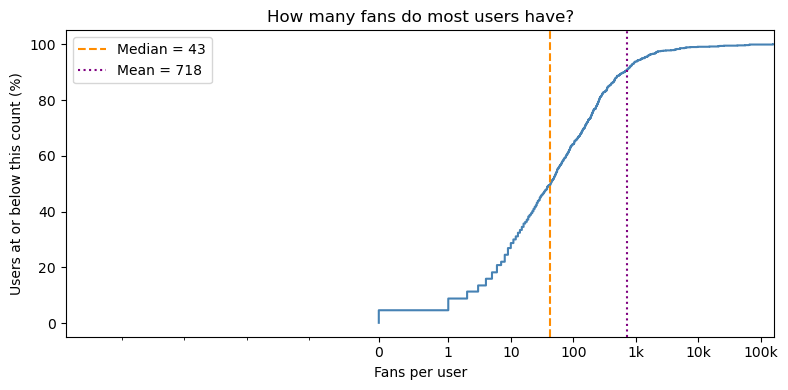

In [6]:
numeric_columns = [
    "follow_user_num",
    "fans_user_num",
    "friend_user_num",
    "register_days",
]

summary = users[numeric_columns].describe(percentiles=[0.5, 0.9, 0.99]).T
display(summary[["min", "50%", "mean", "90%", "99%", "max"]].round(1))

fans = users["fans_user_num"]
top_ten_share = fans.nlargest(10).sum() / fans.sum()
print(f"Share of the total recorded fan count held by the top 10 accounts: "
      f"{top_ten_share:.1%}")

# Each step adds one user. At a given x, the height is the percentage
# of users whose fan count is less than or equal to x.
sorted_fans = np.sort(fans)
cumulative_pct = 100 * np.arange(1, len(fans) + 1) / len(fans)

fig, ax = plt.subplots(figsize=(8, 4))
ax.step(sorted_fans, cumulative_pct, where="post", color="steelblue")
ax.axvline(fans.median(), color="darkorange", linestyle="--",
           label=f"Median = {fans.median():.0f}")
ax.axvline(fans.mean(), color="purple", linestyle=":",
           label=f"Mean = {fans.mean():.0f}")

# A linear region near zero keeps users with zero fans visible.
ax.set_xscale("symlog", linthresh=1)
ax.set_xticks([0, 1, 10, 100, 1_000, 10_000, 100_000])
ax.set_xticklabels(["0", "1", "10", "100", "1k", "10k", "100k"])
ax.set_xlabel("Fans per user")
ax.set_ylabel("Users at or below this count (%)")
ax.set_title("How many fans do most users have?")
ax.legend()
plt.tight_layout()
plt.show()

To read the curve, start at 50% on the vertical axis and move across to
the line. The corresponding fan count is 43. Half of the users have
43 fans or fewer. The mean is about 718, and the maximum is 156,158.

The ten largest accounts, representing 1% of the sample, account for
66.4% of the sum of all recorded fan counts. This explains why the mean
gives such a different impression from the median. The percentage refers
to fan counts summed across accounts; the same person could follow more
than one account.

Account age behaves differently. The mean is about 1,231 days and the
median is 1,234 days. The same summary statistic can be much more
representative for one feature than for another.

##  3.4 Exact counts and their published ranges

Several features appear twice. For example, `fans_user_num` records an
exact count and `fans_user_num_range` assigns the account to a band.
We examine which values each band actually contains and how many users
fall into it.

In [7]:
for column in numeric_columns:
    band_column = f"{column}_range"
    bands = (
        users.groupby(band_column)[column]
        .agg(users="size", smallest_value="min", largest_value="max")
        .sort_values("smallest_value")
    )
    print(f"\n{column}")
    display(bands)


follow_user_num


,users,smallest_value,largest_value
follow_user_num_range,,,
0,9,0,0
"(0,10]",62,1,10
"(10,50]",194,11,50
"(50,100]",134,51,100
"(100,150]",88,101,150
"(150,250]",129,152,249
"(250,500]",175,251,500
500+,209,506,5000



fans_user_num


,users,smallest_value,largest_value
fans_user_num_range,,,
0,46,0,0
"[1,10)",223,1,9
"[10,100)",372,10,97
"[100,1k)",297,100,975
"[1k,5k)",45,1031,4446
"[5k,1w)",8,5003,9603
"[1w,10w)",8,14964,65641
"[10w,100w)",1,156158,156158



friend_user_num


,users,smallest_value,largest_value
friend_user_num_range,,,
0,129,0,0
"[1,5)",210,1,4
"[5,30)",278,5,29
"[30,60)",100,30,59
"[60,120)",98,60,119
"[120,250)",92,120,249
250+,93,253,4690



register_days


,users,smallest_value,largest_value
register_days_range,,,
15-30,4,22,30
31-60,16,34,54
61-90,15,62,88
91-180,39,91,179
181-365,70,183,362
366-730,115,369,729
730+,741,731,3187


The `730+` registration band contains 741 users. Their exact account ages
range from 731 to 3,187 days. The band is convenient when presenting
groups, but it hides substantial differences within the largest group.

At the other extreme, the highest fan-count band contains just one user.
If we later report a long-view rate for this band, it will describe one
person's behaviour, even if that person generated thousands of impressions.
This is why a group-level result should include both its user count and
its impression count.

## 3.5 Anonymous categories and missing values

The README describes `onehot_feat0` through `onehot_feat17` as encoded
categories. A value such as 19 identifies a category. Its numerical
distance from category 2 has no documented meaning.

We can still answer three questions about each feature. How many categories
appear? How common is the most frequent category? How many users have a
missing value? Together these show whether a feature separates users into
large groups, many small groups, or almost no groups at all.

,observed_categories,missing_users,most_common_pct,categories_seen_once
onehot_feat0,2,0,57.0,0
onehot_feat1,7,0,26.7,0
onehot_feat2,23,0,26.5,7
onehot_feat3,394,0,3.8,212
onehot_feat4,13,33,38.2,2
onehot_feat5,5,0,99.5,3
onehot_feat6,3,0,56.4,0
onehot_feat7,37,0,9.7,7
onehot_feat8,283,0,2.2,83
onehot_feat9,7,0,22.7,0


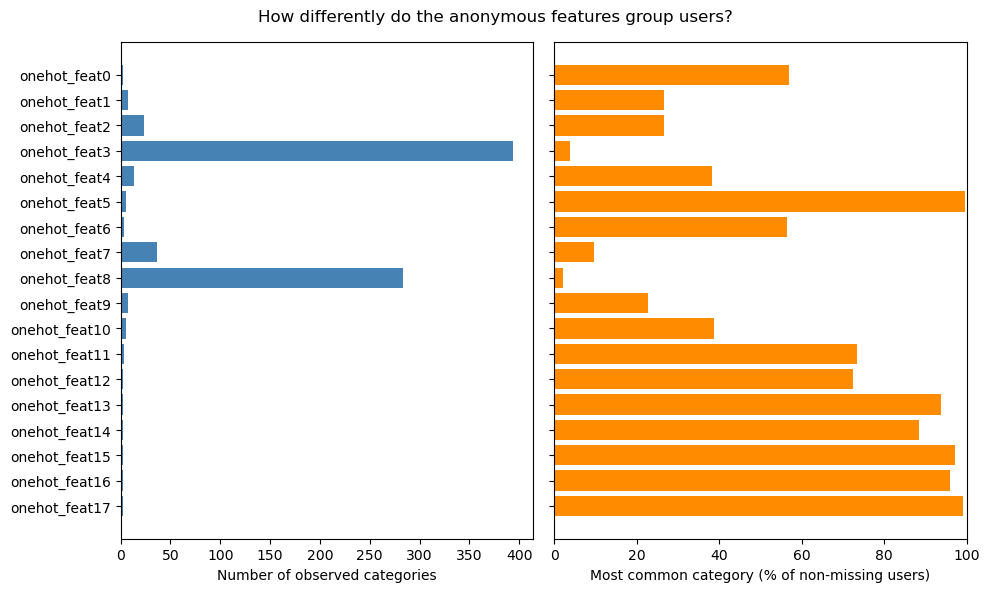

,users
No missing fields,934
onehot_feat4,33
"onehot_feat12, onehot_feat13, onehot_feat14, onehot_feat15, onehot_feat16, onehot_feat17",33


In [8]:
anonymous = users.filter(regex=r"^onehot_feat\d+$")

profile = pd.DataFrame({
    "observed_categories": anonymous.nunique(),
    "missing_users": anonymous.isna().sum(),
    "most_common_pct": [
        100 * anonymous[col].value_counts(normalize=True).iloc[0]
        for col in anonymous
    ],
    "categories_seen_once": [
        anonymous[col].value_counts().eq(1).sum()
        for col in anonymous
    ],
})
display(profile.round(1))

fig, axes = plt.subplots(1, 2, figsize=(10, 6), sharey=True)
axes[0].barh(profile.index, profile["observed_categories"], color="steelblue")
axes[1].barh(profile.index, profile["most_common_pct"], color="darkorange")
axes[0].invert_yaxis()
axes[0].set_xlabel("Number of observed categories")
axes[1].set_xlabel("Most common category (% of non-missing users)")
axes[1].set_xlim(0, 100)
fig.suptitle("How differently do the anonymous features group users?")
plt.tight_layout()
plt.show()

# Count patterns across users to see which fields are missing together.
missing_patterns = anonymous.isna().apply(
    lambda row: ", ".join(row.index[row]) if row.any() else "No missing fields",
    axis=1,
)
display(missing_patterns.value_counts().rename("users").to_frame())

`onehot_feat3` has 394 observed categories. Of these, 212 appear for only
one user each. A model using these categories could learn details specific
to individual accounts. At the opposite extreme, `onehot_feat5` takes the
same value for 995 users and distinguishes only a handful of exceptions.

The missing values form two distinct patterns. For 33 users, only
`onehot_feat4` is missing. For another 33, `onehot_feat12` through
`onehot_feat17` are missing together. The remaining 934 users have complete
anonymous features. Dropping every incomplete row would therefore remove
66 users, even though their interpretable profile fields are available.

##  3.6 What the profile table contributes to the project

The sample contains substantial differences in activity, account age,
authorship, and social network size. We can use these characteristics
to describe who is represented in an evaluation and whether a result
holds across different groups of users.

A first question for the interaction data is: within tab 1, do users who
have uploaded a video have different long-view rates from users who have
never uploaded one? We can join on `user_id`, calculate one long-view rate
per user, and compare the distributions in the two groups. This gives
each person equal weight, consistent with the exploration above.

Using profile fields for prediction raises a separate timing question.
The profile table gives one record per user without a measurement date.
Before using activity labels or fan counts to predict a past impression,
we need to establish when those values were recorded.

# 4.1 Exploring the KuaiRand-1K video catalog

The basic video table describes the items available in the dataset.
Each row represents a video. In this notebook, a video shown once and
a video shown a thousand times receive the same weight.

We want to understand which video characteristics could be useful when
a recommender encounters a video with no interaction history. We begin
by checking the video key and the coverage of each metadata field.

In [9]:
from pathlib import Path
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

path = Path("KuaiRand-1K") / "data" / "video_features_basic_1k.csv"

# Repeated labels take much less memory when stored as categories.
# Keep music IDs in 64 bits because some exceed the 32-bit integer range.
videos = pd.read_csv(
    path,
    dtype={
        "video_id": "Int32",
        "author_id": "Int32",
        "music_id": "Int64",
        "video_type": "category",
        "upload_type": "category",
        "upload_dt": "category",
        "tag": "category",
    },
)

print(f"Catalog size: {len(videos):,} rows × {videos.shape[1]} columns")
print(f"Missing video IDs: {videos['video_id'].isna().sum():,}")
print(f"Repeated video IDs: {videos['video_id'].duplicated().sum():,}")
print(f"DataFrame memory: {videos.memory_usage(deep=True).sum() / 2**20:.0f} MiB")

overview = pd.DataFrame({
    "distinct_values": videos.nunique(),
    "missing_videos": videos.isna().sum(),
    "missing_pct": videos.isna().mean().mul(100).round(2),
})
display(overview)
display(videos.head(5))

Catalog size: 4,371,868 rows × 12 columns
Missing video IDs: 0
Repeated video IDs: 0
DataFrame memory: 271 MiB


,distinct_values,missing_videos,missing_pct
video_id,4371868,0,0.00
author_id,1407475,0,0.00
video_type,3,0,0.00
upload_dt,235,58,0.00
upload_type,32,0,0.00
visible_status,3,5,0.00
video_duration,212211,573057,13.11
server_width,3109,7,0.00
server_height,3997,7,0.00
music_id,2622610,0,0.00


,video_id,author_id,video_type,upload_dt,upload_type,visible_status,video_duration,server_width,server_height,music_id,music_type,tag
0,0,7349781,NORMAL,2022-04-10,LongImport,0.0,87433.0,720.0,1280.0,9155697141,9.0,39
1,1,2103883,NORMAL,2022-04-10,Kmovie,0.0,218066.0,720.0,1280.0,6355810746,9.0,2
2,2,5067285,NORMAL,2022-04-09,ShortImport,0.0,9233.0,720.0,1280.0,6618412736,4.0,1
3,3,7048760,NORMAL,2022-04-11,Web,0.0,16433.0,720.0,1280.0,9161677205,9.0,7
4,4,8635271,NORMAL,2022-04-09,Web,0.0,38766.0,720.0,1280.0,9141092381,9.0,9


The public release contains 4,371,868 rows and 12 columns. Each video ID
is present and unique. This makes `video_id` suitable for joining many
impressions to one metadata row.

Duration has 573,057 missing values and tags are missing for 137,484 videos.
These gaps affect different project questions: duration matters for
interpreting a long view, while tags could help describe a user's topic
preferences. We examine each separately.

## 4.2 Duration and upload format
The public release contains 4,371,868 rows and 12 columns. Each video ID
is present and unique. This makes `video_id` suitable for joining many
impressions to one metadata row.

Duration has 573,057 missing values and tags are missing for 137,484 videos.
These gaps affect different project questions: duration matters for
interpreting a long view, while tags could help describe a user's topic
preferences. We examine each separately.

Missing duration: 573,057
Recorded zero duration: 0
Negative duration: 0
At most 18 seconds, among positive durations: 35.7%


0.25     12.062
0.50     35.100
0.75     97.533
0.90    192.966
0.99    508.000
Name: seconds, dtype: float64

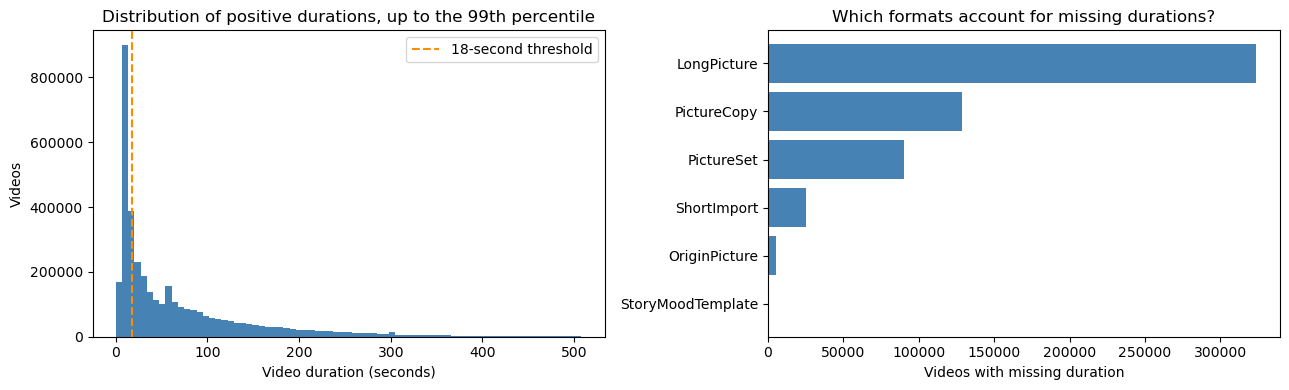

,videos,missing,missing_pct
upload_type,,,
LongPicture,323304,323303,100.0
PictureCopy,128750,128507,99.81
PictureSet,90383,90383,100.0
ShortImport,872196,25183,2.89
OriginPicture,5345,5340,99.91
StoryMoodTemplate,248,248,100.0
UNKNOWN,16698,72,0.43
ShortCamera,250519,14,0.01


In [10]:
duration_ms = videos["video_duration"]
seconds = duration_ms[duration_ms > 0] / 1000

print(f"Missing duration: {duration_ms.isna().sum():,}")
print(f"Recorded zero duration: {duration_ms.eq(0).sum():,}")
print(f"Negative duration: {duration_ms.lt(0).sum():,}")
print(f"At most 18 seconds, among positive durations: {seconds.le(18).mean():.1%}")
display(seconds.quantile([0.25, 0.50, 0.75, 0.90, 0.99]).rename("seconds"))

formats = (
    videos.assign(missing_duration=duration_ms.isna())
    .groupby("upload_type", observed=True)
    .agg(videos=("video_id", "size"), missing=("missing_duration", "sum"))
)
formats["missing_pct"] = 100 * formats["missing"] / formats["videos"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Limit the display to the 99th percentile so the main distribution is visible.
# All positive durations were included in the statistics above.
upper = seconds.quantile(0.99)
axes[0].hist(seconds[seconds <= upper], bins=75, color="steelblue")
axes[0].axvline(18, color="darkorange", linestyle="--", label="18-second threshold")
axes[0].set(xlabel="Video duration (seconds)", ylabel="Videos",
            title="Distribution of positive durations, up to the 99th percentile")
axes[0].legend()

largest_sources = formats.nlargest(6, "missing").sort_values("missing")
axes[1].barh(largest_sources.index.astype(str), largest_sources["missing"],
             color="steelblue")
axes[1].set(xlabel="Videos with missing duration",
            title="Which formats account for missing durations?")

plt.tight_layout()
plt.show()

display(formats.sort_values("missing", ascending=False).head(8).round(2))

Among videos with a positive duration, the median is 35.1 seconds and
35.7% last at most 18 seconds. For over a third of the videos with known
duration, a long view therefore requires watching the entire video.

The basic metadata contains 573,057 missing durations and zero recorded
durations equal to zero. Three formats account for 94.6% of the missing
values: `LongPicture`, `PictureCopy`, and `PictureSet`. For example,
323,303 of 323,304 `LongPicture` items have no recorded duration.

This suggests a specific check for the interaction analysis. For impressions
with `duration_ms == 0`, join the basic metadata by `video_id` and inspect
both `upload_type` and `video_duration`. The 13.1% missing rate here counts
catalog videos. The 8.0% zero-duration rate in the earlier notebook counts
standard-feed impressions. The join will show how the two groups overlap.

## 4.3 Topic coverage and multi-tag videos

A tag field such as "20,43" assigns two topic IDs to one video. Counting
raw strings would treat "20,43" as a third topic separate from "20" and
"43". We split the combinations and count how many videos carry each
individual tag.

Many videos share exactly the same combination. We can count each
combination first, split it once, and use its frequency as a weight.
This avoids building a table with millions of additional rows.

Distinct individual tags: 58
Videos with a recorded tag: 96.9%


0     137484
1    3289054
2     918131
3      26293
4        903
5          3
Name: number_of_videos, dtype: int64

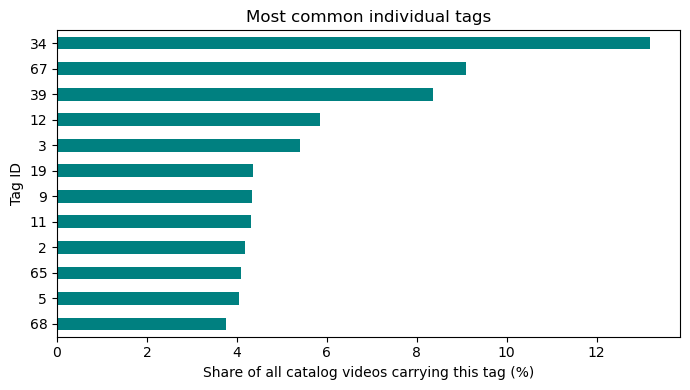

In [11]:
combinations = videos["tag"].value_counts()
videos_per_tag = Counter()
videos_per_tag_count = Counter()

for combination, frequency in combinations.items():
    tags = {tag.strip() for tag in str(combination).split(",") if tag.strip()}
    videos_per_tag_count[len(tags)] += int(frequency)
    for tag in tags:
        videos_per_tag[tag] += int(frequency)

videos_per_tag_count[0] += int(videos["tag"].isna().sum())

tag_counts = pd.Series(videos_per_tag).sort_values(ascending=False)
tag_counts.index.name = "tag_id"
print(f"Distinct individual tags: {len(tag_counts)}")
print(f"Videos with a recorded tag: {videos['tag'].notna().mean():.1%}")
display(pd.Series(videos_per_tag_count).sort_index().rename("number_of_videos"))

top_tags_pct = 100 * tag_counts.head(12).sort_values() / len(videos)
ax = top_tags_pct.plot.barh(figsize=(7, 4), color="teal")
ax.set(xlabel="Share of all catalog videos carrying this tag (%)",
       ylabel="Tag ID", title="Most common individual tags")
plt.tight_layout()
plt.show()

The 1,188 observed tag combinations reduce to 58 individual tag IDs.
At least one tag is available for 96.9% of the catalog, and 21.6% of all
videos have two or more tags. Tag 34 appears on 576,886 videos, or 13.2%
of the catalog. A video can contribute to several bars.

This gives us a practical way to transfer information across video IDs.
For example, when a new video carries tags 20 and 43, we can look up the
user's earlier viewing behaviour for each tag. The catalog establishes
that these tags are widely available. The logs will tell us whether an
individual user has enough past observations for them.

## 4.4 Authors as a possible link between videos

A video may be new to the recommender even when its creator is familiar.
To explore that possibility, we count the catalog videos associated with
each author.

We use two denominators. If we select an author, how many videos belong
to that author? If we select a video, how large is its author's catalog?
Authors with many videos contribute once to the first calculation and
many times to the second.

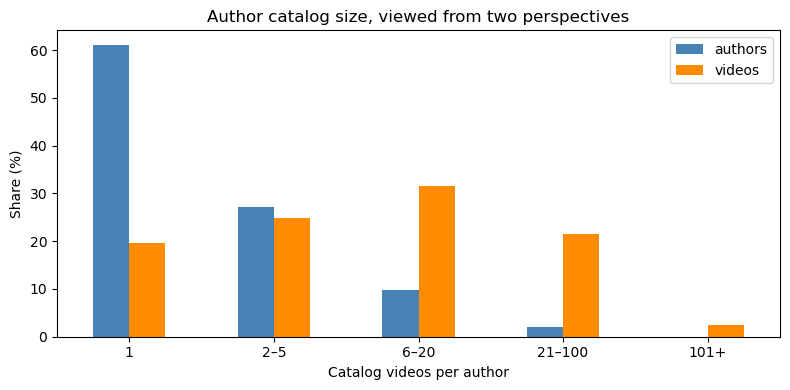

Distinct author IDs: 1,407,475


,authors,videos
1,859462,859462
2–5,381690,1085109
6–20,138416,1379302
21–100,27268,937473
101+,639,110522


In [12]:
videos_per_author = videos.groupby("author_id").size()

# Each author belongs to one catalog-size group.
size_group = pd.cut(
    videos_per_author,
    bins=[0, 1, 5, 20, 100, np.inf],
    labels=["1", "2–5", "6–20", "21–100", "101+"],
)

by_size = pd.DataFrame({
    "authors": videos_per_author.groupby(size_group, observed=True).size(),
    "videos": videos_per_author.groupby(size_group, observed=True).sum(),
})
shares = by_size.div(by_size.sum()).mul(100)

ax = shares.plot.bar(figsize=(8, 4), color=["steelblue", "darkorange"], rot=0)
ax.set(xlabel="Catalog videos per author", ylabel="Share (%)",
       title="Author catalog size, viewed from two perspectives")
plt.tight_layout()
plt.show()

print(f"Distinct author IDs: {len(videos_per_author):,}")
display(by_size)

There are 1,407,475 distinct author IDs. Of these, 859,462 appear on
exactly one video. Look at the two bars above "1": these authors represent
61.1% of authors but account for only 19.7% of videos.

This distinction matters for the project. About four in five catalog
videos have an author who appears on another catalog item. The next
question is more demanding: when a particular user receives a new video,
have they already seen that author before that impression? Answering it
requires the user's chronological interaction history.

## 4.5 Upload dates and the training cutoff

The standard training period ends on 21 April 2022. A video uploaded
on 22 April or later could not have accumulated training impressions
before that cutoff.

Upload date helps distinguish two reasons for an unfamiliar video ID:
the item may have been published recently, or it may already have existed
without appearing in the observed training logs.

,videos,catalog_pct
Before training,1198784,27.42
During training,1437076,32.87
During evaluation,1735950,39.71
After evaluation,0,0.00
Missing date,58,0.00


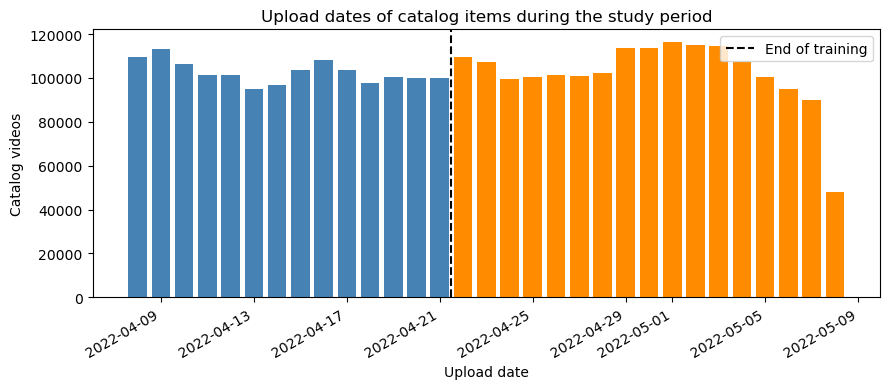

In [13]:
# Count the repeated date labels before converting them to timestamps.
daily_uploads = videos["upload_dt"].value_counts()
daily_uploads.index = pd.to_datetime(
    daily_uploads.index.astype(str), format="%Y-%m-%d"
)
daily_uploads = daily_uploads.sort_index()

train_start = pd.Timestamp("2022-04-08")
train_end = pd.Timestamp("2022-04-21")
test_end = pd.Timestamp("2022-05-08")

upload_period = pd.Series({
    "Before training": daily_uploads[daily_uploads.index < train_start].sum(),
    "During training": daily_uploads.loc[train_start:train_end].sum(),
    "During evaluation": daily_uploads.loc["2022-04-22":test_end].sum(),
    "After evaluation": daily_uploads[daily_uploads.index > test_end].sum(),
    "Missing date": videos["upload_dt"].isna().sum(),
})
display(pd.DataFrame({
    "videos": upload_period,
    "catalog_pct": (100 * upload_period / len(videos)).round(2),
}))

window = daily_uploads.reindex(pd.date_range(train_start, test_end), fill_value=0)
colors = np.where(window.index <= train_end, "steelblue", "darkorange")

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(window.index, window.values, color=colors)
ax.axvline(train_end + pd.Timedelta(hours=12), color="black", linestyle="--",
           label="End of training")
ax.set(xlabel="Upload date", ylabel="Catalog videos",
       title="Upload dates of catalog items during the study period")
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

Of all catalog videos, 1,198,784 were uploaded before the training window,
1,437,076 during training, and 1,735,950 during evaluation. Another
58 have no recorded upload date. The chart describes videos included in
KuaiRand-1K, so its daily counts cannot be read as total platform uploads.

The 39.7% uploaded during evaluation and the earlier finding that about
81% of evaluation impressions involve an unseen video answer different
questions. The first counts distinct catalog items. The second weights
videos by how often they were shown. To connect them, take the evaluation
impressions with unseen video IDs and measure what share involved videos
uploaded after the cutoff.

# 5.1 Exploring video-level statistics in KuaiRand-1K

The basic video table describes the content of a video, including its author,
tags and duration. The statistics table describes what happened when the
platform distributed that video during the collection month.

Each row summarizes a video across the recorded days and app scenarios.
`counts` gives the number of observations contributing to that summary.
Fields such as `show_cnt` and `long_time_play_cnt` are averages over those
observations. This explains why a count can contain a decimal value.

Our first question is whether videos with higher average exposure also tend
to generate more long views per exposure.

In [14]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Run from the project folder containing KuaiRand-1K.
stats_path = Path("KuaiRand-1K/data/video_features_statistic_1k.csv")

preview = pd.read_csv(stats_path, nrows=3)

print(f"File size: {stats_path.stat().st_size / 2**30:.2f} GiB")
print(f"Number of columns: {len(preview.columns)}")

# One feature per row makes the full list easier to inspect.
with pd.option_context("display.max_rows", None):
    display(preview.T.rename(columns={0: "Video A", 1: "Video B", 2: "Video C"}))

File size: 3.14 GiB
Number of columns: 52


,Video A,Video B,Video C
video_id,0.000000e+00,1.000000e+00,2.000000e+00
counts,1.020000e+02,1.360000e+02,9.100000e+01
show_cnt,2.579686e+03,4.027993e+03,6.667033e+02
show_user_num,2.308324e+03,3.368368e+03,5.472198e+02
play_cnt,8.168824e+02,2.116250e+03,4.256813e+02
play_user_num,7.131765e+02,1.864044e+03,3.865385e+02
play_duration,2.767915e+07,8.592152e+07,4.197048e+06
complete_play_cnt,1.952549e+02,1.305074e+02,8.020879e+01
complete_play_user_num,1.830980e+02,1.259412e+02,7.546154e+01
valid_play_cnt,4.430196e+02,7.176765e+02,9.572527e+01


### Reading the first three video profiles

Each column in the preview represents one video. The `counts` field records
how many day–scenario observations contribute to its monthly summary.
For example, Video A has 102 contributing observations and an average of
about 2,580 shows per observation.

The three videos illustrate why the choice of denominator matters:

| Video | Average shows | Long views per 100 shows | Likes per 100 shows |
|---|---:|---:|---:|
| A | 2,580 | 12.36 | 0.25 |
| B | 4,028 | 13.65 | 0.95 |
| C | 667 | 11.98 | 0.99 |

Video A receives almost four times as much exposure as Video C. Once we
express the outcomes per 100 shows, they generate a similar number of
long views, while C receives about four times as many likes as A.

Among these three examples, B ranks first for long views per exposure
and C ranks first for likes per exposure. The small difference between
B and C on likes also matters: a change in rank can correspond to a
small change in the underlying rate. These examples illustrate the
ranking question that we will later investigate across users and videos.

## 5.2 Coverage of the main exposure and engagement fields

We select fields that describe exposure, playback and explicit appreciation.
For each field, we count missing values and recorded zeros across the full
file. A missing like count and a recorded count of zero have different
interpretations, so we keep them separate.

During the same pass, we sample rows from throughout the file. Every row
has the same probability of selection. The sample therefore describes
catalog videos, with equal weight given to each sampled row.

In [15]:
columns = [
    "video_id", "counts", "show_cnt", "show_user_num",
    "play_cnt", "long_time_play_cnt", "complete_play_cnt", "like_cnt",
]
measures = [col for col in columns if col != "video_id"]

rng = np.random.default_rng(42)
sample_probability = 0.005  # About 5,000 rows per million.
sample_parts = []
total_rows = 0

audit = pd.DataFrame(
    0, index=measures, columns=["missing", "zero", "negative"], dtype="int64"
)

for chunk in pd.read_csv(stats_path, usecols=columns, chunksize=50_000):
    values = chunk[measures]
    total_rows += len(chunk)

    audit["missing"] += values.isna().sum()
    audit["zero"] += values.eq(0).sum()
    audit["negative"] += values.lt(0).sum()

    keep = rng.random(len(chunk)) < sample_probability
    sample_parts.append(chunk.loc[keep, columns].copy())

stats_sample = pd.concat(sample_parts, ignore_index=True)

audit["missing_pct"] = 100 * audit["missing"] / total_rows
audit["zero_pct"] = 100 * audit["zero"] / total_rows

print(f"Rows in the full file: {total_rows:,}")
print(f"Rows in the sample: {len(stats_sample):,}")
display(audit.round(2))

# Reuse the sample in future sessions without scanning the large file again.
stats_sample.to_csv("video_statistics_sample.csv.gz", index=False)

Rows in the full file: 4,371,868
Rows in the sample: 21,866


,missing,zero,negative,missing_pct,zero_pct
counts,0,0,0,0.0,0.00
show_cnt,0,0,0,0.0,0.00
show_user_num,0,0,0,0.0,0.00
play_cnt,0,7,0,0.0,0.00
long_time_play_cnt,0,3397,0,0.0,0.08
complete_play_cnt,0,6842,0,0.0,0.16
like_cnt,0,6550,0,0.0,0.15


The full file contains 4,371,868 rows. Across the seven measures examined,
we found no missing or negative values. Every row has a positive `show_cnt`,
so exposure is an available denominator throughout the table.

Zeros have different frequencies across outcomes. Only 7 rows have zero
plays, 3,397 have zero long views, and 6,550 have zero likes. The displayed
0.00% for zero plays is due to rounding.

Only 0.15% of video rows have zero recorded likes in the monthly statistics.
By comparison, about 1.56% of individual impressions in the standard logs
resulted in a like. These figures answer different questions. A video has
many opportunities to receive a like during the month, while the prediction
target concerns one user reacting to one impression. Likes therefore remain
a rare outcome for our prediction task.

## 5.3 From average counts to exposure-adjusted measures

A video can accumulate many long views because it receives many exposures.
To separate distribution from audience response, we calculate long views
per 100 exposures. We also calculate likes per 100 exposures so that both
outcomes use the same denominator.

We leave the rate undefined when exposure is zero or missing. We report
the distribution across videos, giving each sampled video equal weight.

In [16]:
# Replace invalid denominators with NaN. Preserve recorded zero outcomes.
positive_exposure = stats_sample["show_cnt"].where(stats_sample["show_cnt"] > 0)

stats_sample["long_views_per_100_shows"] = (
    100 * stats_sample["long_time_play_cnt"] / positive_exposure
)
stats_sample["likes_per_100_shows"] = (
    100 * stats_sample["like_cnt"] / positive_exposure
)

summary_columns = [
    "counts", "show_cnt", "play_cnt", "long_time_play_cnt", "like_cnt",
    "long_views_per_100_shows", "likes_per_100_shows",
]

summary = stats_sample[summary_columns].describe(
    percentiles=[0.50, 0.90, 0.99]
).T

display(summary[["count", "mean", "50%", "90%", "99%", "max"]].round(3))

,count,mean,50%,90%,99%,max
counts,21866.0,66.096,57.000,134.000,184.000,188.000
show_cnt,21866.0,6072.874,1541.515,12351.332,73114.173,1455537.714
play_cnt,21866.0,4633.414,779.352,9047.826,60075.887,1479949.929
long_time_play_cnt,21866.0,2106.543,243.018,3826.151,30965.080,538918.667
like_cnt,21866.0,109.935,13.428,188.194,1768.319,24318.833
long_views_per_100_shows,21866.0,22.273,17.578,48.950,68.104,88.231
likes_per_100_shows,21866.0,2.027,0.935,5.084,14.744,68.361


The descriptive statistics cover 21,866 sampled video rows, with equal
weight given to each row. Median exposure is about 1,542 shows per recorded
day–scenario observation. Mean exposure is much higher, at about 6,073,
and the 99th percentile reaches 73,114. A relatively small group of highly
exposed videos therefore pulls the mean upwards.

Differences remain after adjusting for exposure. The median video generates
17.58 long views per 100 shows, and the 90th percentile reaches 48.95.
For likes, the corresponding values are 0.94 and 5.08 per 100 shows.

The mean of 22.27 long views per 100 shows describes an average across
video-level rates. Each sampled video contributes once, even when two
videos have very different exposure. An impression-level average would
give more weight to highly exposed videos.

For the project, the next question is whether high-exposure videos also
tend to have high response rates. The separate distributions above cannot
establish that relationship on their own.

## 5.4 Do more widely shown videos generate more long views per exposure?

We group videos by their average number of shows per recorded day and
scenario. Within each group, we calculate the median number of long views
per 100 shows. The interval between the 25th and 75th percentiles describes
how much the middle half of videos varies within that group.

We report the number of sampled videos in each group because a pattern
based on a handful of videos is harder to interpret.

,videos,median,q25,q75
exposure_group,,,,
"(1, 10]",138,6.64,3.82,10.49
"(10, 100]",1542,6.28,3.25,10.93
"(100, 1,000]",7004,12.87,5.30,26.54
"Above 1,000",13182,23.46,10.57,40.40


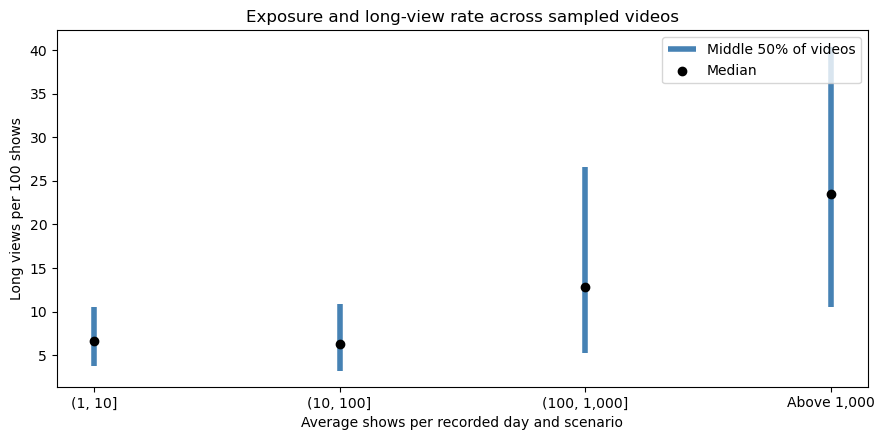

In [17]:
plot_data = stats_sample.loc[
    stats_sample["show_cnt"].gt(0)
    & stats_sample["long_time_play_cnt"].ge(0)
].copy()

plot_data["exposure_group"] = pd.cut(
    plot_data["show_cnt"],
    bins=[0, 1, 10, 100, 1_000, np.inf],
    labels=["(0, 1]", "(1, 10]", "(10, 100]", "(100, 1,000]", "Above 1,000"],
)

by_exposure = (
    plot_data.groupby("exposure_group", observed=True)["long_views_per_100_shows"]
    .agg(
        videos="size",
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
    )
)

display(by_exposure.round(2))

x = np.arange(len(by_exposure))
fig, ax = plt.subplots(figsize=(9, 4.5))

ax.vlines(x, by_exposure["q25"], by_exposure["q75"],
          color="steelblue", linewidth=4, label="Middle 50% of videos")
ax.scatter(x, by_exposure["median"], color="black", zorder=3, label="Median")

ax.set_xticks(x, by_exposure.index.astype(str))
ax.set_xlabel("Average shows per recorded day and scenario")
ax.set_ylabel("Long views per 100 shows")
ax.set_title("Exposure and long-view rate across sampled videos")
ax.legend()
plt.tight_layout()
plt.show()

The first two exposure groups have similar median rates: 6.64 and 6.28
long views per 100 shows. The median then rises to 12.87 in the 100–1,000
group and to 23.46 above 1,000 shows. The association is most visible in
the two higher exposure groups. The lowest displayed group contains only
138 videos, compared with 13,182 in the highest group.

The vertical bars show the middle half of the videos within each group.
Above 1,000 shows, this interval runs from 10.57 to 40.40 long views per
100 shows. There is also substantial overlap across groups. For example,
the upper quartile of the 100–1,000 group starts at 26.54, above the median
of the highest-exposure group.

Exposure therefore provides a useful baseline, but videos with similar
exposure can produce very different viewing outcomes. One possible
explanation is that the groups contain different mixes of short videos,
long videos and items with no recorded duration. We investigate this next.

## Comparing exposure groups within video-duration bands

KuaiRand's long-view rule changes at 18 seconds. A 12-second video reaches
the threshold when the viewer watches the full 12 seconds. A 60-second
video reaches it after 18 seconds. A comparison that mixes these videos
may partly reflect differences in duration.

We join the sampled statistics to the basic video metadata using `video_id`.
We then repeat the exposure analysis within four duration groups: missing
or zero duration, up to 18 seconds, over 18 to 60 seconds, and over 60
seconds. The missing-duration group is kept visible because our earlier
exploration linked many of these items to picture-based upload formats.

In [19]:
basic_path = stats_path.with_name("video_features_basic_1k.csv")
sample_ids = set(stats_sample["video_id"])

duration_parts = []
for chunk in pd.read_csv(
    basic_path,
    usecols=["video_id", "video_duration"],
    chunksize=100_000,
):
    duration_parts.append(chunk.loc[chunk["video_id"].isin(sample_ids)])

sample_durations = pd.concat(duration_parts, ignore_index=True)

analysis = stats_sample.merge(
    sample_durations,
    on="video_id",
    how="left",
    validate="one_to_one",
    indicator=True,
)

# A missing metadata row and a matched row with missing duration
# are different cases. Count them separately before the analysis.
matched = analysis["_merge"].eq("both")
print(f"Sampled rows: {len(analysis):,}")
print(f"Rows matched to basic metadata: {matched.sum():,}")
print(f"Rows without a metadata match: {(~matched).sum():,}")
print(f"Matched rows with missing duration: "
      f"{(matched & analysis['video_duration'].isna()).sum():,}")

analysis = analysis.loc[matched].copy()
seconds = analysis["video_duration"] / 1000

duration_labels = ["Missing or zero", "Up to 18 s", "Over 18 to 60 s", "Over 60 s"]

analysis["duration_group"] = pd.cut(
    seconds,
    bins=[0, 18, 60, np.inf],
    labels=duration_labels[1:],
    right=True,
)
analysis["duration_group"] = (
    analysis["duration_group"].cat.add_categories(["Missing or zero"])
)
analysis.loc[seconds.isna() | seconds.eq(0), "duration_group"] = "Missing or zero"

print("\nVideos by duration group:")
display(analysis["duration_group"].value_counts().reindex(duration_labels))

Sampled rows: 21,866
Rows matched to basic metadata: 21,866
Rows without a metadata match: 0
Matched rows with missing duration: 2,925

Videos by duration group:


duration_group
Missing or zero    2925
Up to 18 s         6797
Over 18 to 60 s    4862
Over 60 s          7282
Name: count, dtype: int64

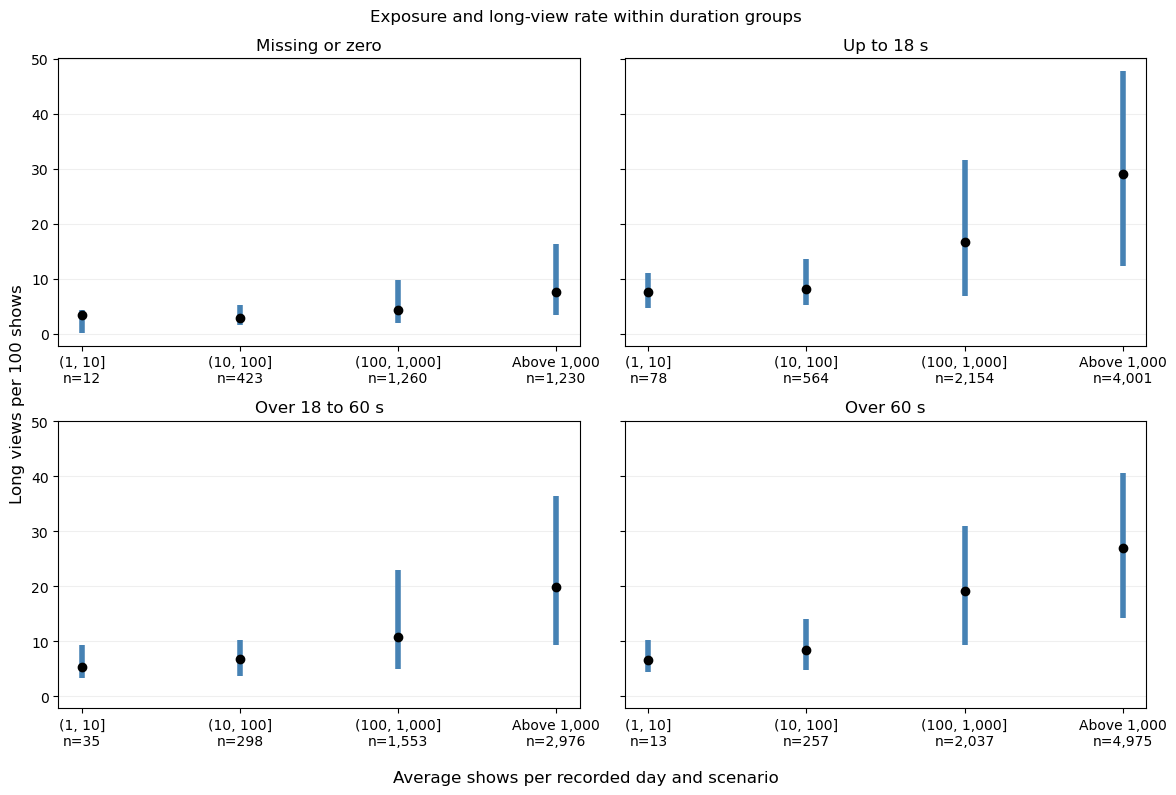

,duration_group,exposure_group,videos,median,q25,q75
0,Up to 18 s,"(1, 10]",78,7.71,4.79,11.15
1,Up to 18 s,"(10, 100]",564,8.22,5.29,13.56
2,Up to 18 s,"(100, 1,000]",2154,16.73,6.83,31.65
3,Up to 18 s,"Above 1,000",4001,29.09,12.28,47.69
4,Over 18 to 60 s,"(1, 10]",35,5.38,3.42,9.27
5,Over 18 to 60 s,"(10, 100]",298,6.79,3.69,10.25
6,Over 18 to 60 s,"(100, 1,000]",1553,10.85,4.92,23.06
7,Over 18 to 60 s,"Above 1,000",2976,19.93,9.34,36.44
8,Over 60 s,"(1, 10]",13,6.70,4.36,10.23
9,Over 60 s,"(10, 100]",257,8.36,4.72,14.13


In [20]:
exposure_labels = ["(0, 1]", "(1, 10]", "(10, 100]", "(100, 1,000]", "Above 1,000"]

analysis["exposure_group"] = pd.cut(
    analysis["show_cnt"],
    bins=[0, 1, 10, 100, 1_000, np.inf],
    labels=exposure_labels,
)

analysis["long_views_per_100_shows"] = (
    100 * analysis["long_time_play_cnt"]
    / analysis["show_cnt"].where(analysis["show_cnt"] > 0)
)

by_duration = (
    analysis.groupby(["duration_group", "exposure_group"], observed=True)
    ["long_views_per_100_shows"]
    .agg(
        videos="count",
        median="median",
        q25=lambda values: values.quantile(0.25),
        q75=lambda values: values.quantile(0.75),
    )
    .reset_index()
)

# Display only exposure bands that contain videos in this sample.
active_bands = [
    band for band in exposure_labels
    if band in by_duration["exposure_group"].values
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
x = np.arange(len(active_bands))

for ax, duration in zip(axes.flat, duration_labels):
    group = (
        by_duration.loc[by_duration["duration_group"] == duration]
        .set_index("exposure_group")
        .reindex(active_bands)
    )

    ax.vlines(x, group["q25"], group["q75"], color="steelblue", linewidth=4)
    ax.scatter(x, group["median"], color="black", zorder=3)

    counts = group["videos"].fillna(0).astype(int)
    ax.set_xticks(x, [f"{band}\nn={n:,}" for band, n in zip(active_bands, counts)])
    ax.set_title(duration)
    ax.grid(axis="y", alpha=0.2)

fig.supylabel("Long views per 100 shows")
fig.supxlabel("Average shows per recorded day and scenario")
fig.suptitle("Exposure and long-view rate within duration groups")
plt.tight_layout()
plt.show()

display(by_duration.round(2))

Across all four duration groups, median long views per 100 shows are higher
in the highest exposure band than in the 100–1,000 band. The difference is
largest for videos up to 18 seconds (+12.36) and smallest for items with
missing or zero duration (+3.25). Differences in the duration mix may
contribute to the overall pattern, while the association remains visible
within each duration group.

Videos with similar exposure and duration still vary substantially. Among
highly exposed videos up to 18 seconds long, the middle half ranges from
12.28 to 47.69 long views per 100 shows. The catalog analysis establishes
a baseline for our next question: can a user's prior interactions with a
topic or author improve the ranking of videos beyond what their general
performance and duration already tell us?